In [ ]:
import numpy as np 
import matplotlib.pyplot as plt

M = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]]) # identidade manual
V1 = np.array([1,3])
V2 = np.array([2,4])
M1 = np.array([[2, 4, 6], [2, 2, 2], [14, 16, 18]])
M2 = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
transposta = M1.T # .T é o método do numpy pra transpor matrizes
I = np.eye(3) # identidade do numPy
x = np.array([1,1])
e1 = np.array([1,0])
e2 = np.array([0,1])

#proj de V1 sobre V2
proj = (V2 @ V1) / (V1 @ V1) * V1

#norma / modulo de um vetor
norma1 = np.linalg.norm(V1)
norma2 = np.linalg.norm(V2)

#nativo do python
mult = M1 @ M2 # o @ é usado pra multiplicaçao de matrizes
multV = V1 @ V2 # usado pra produto escalar tambem

#angulo entre V1 e V2
theta = np.arccos(multV / (norma1 * norma2)) #usa arccos pra achar o theta ja que arccos é cos^-1 -> (V1@V2) = |V1| * |V2| * cos theta
print("Angulo entre V1 e V2: ", np.degrees(theta))

print(np.allclose(M, I)) # iguais
print("\n", M1,"\n\n" ,M2)
print("\n")
print(mult) 

# print(M.shape, M.ndim, M.dtype) # formato da matriz, ndimensoes, tipo dos numeros

#print("\n")
#print("\n",V1,"\n",V2) 
print("\n")
print(multV) # produto escalar: 1*2 + 3*4

#print(V1 + V2) # -> [1+2, 3+4]
#print(V1 * V2) # -> [1*2, 3*4]
#print(2 * V1) # -> [2*1, 2*3]
#print(2 ** V1) # -> [2^1, 2^3]
#print(V1 ** 2) # -> [1^2, 3^2]





C:\Users\fabri\AppData\Local\Temp\ipykernel_38872\2842704369.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


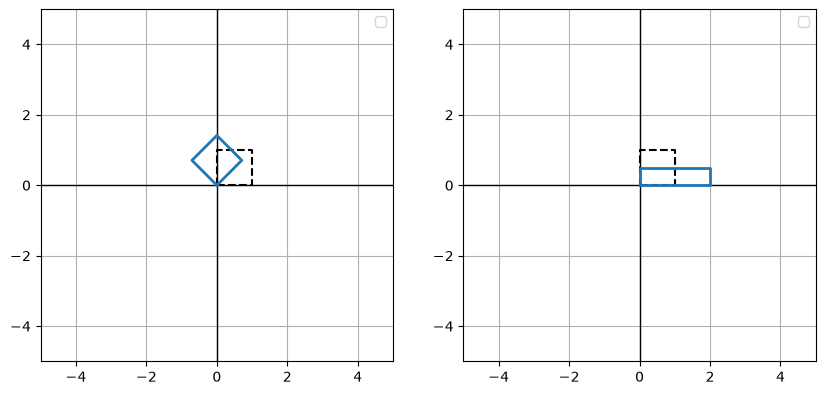

In [ ]:
def rotacao(theta): 
    c = np.cos(theta)
    s = np.sin(theta)
    return np.array([[c, -s], [s, c]])

transformacoes = {
    "Rotação 45°":      rotacao(np.pi / 4),
    "Escala (2, 0.5)":  np.array([[2.0, 0.0], [0.0, 0.5]])
}

quadrado = np.array([[0, 1, 1, 0, 0],
                     [0, 0, 1, 1, 0]])

fig, axes = plt.subplots(1, 2, figsize=(10,5))

for ax, (nome, T) in zip(np.atleast_1d(axes), transformacoes.items()):
    # 1. Aplica a transformação no quadrado e nos vetores da base (e1, e2)
    q_trans = T @ quadrado
    e1t = T @ e1
    e2t = T @ e2

    #mostra os 4 quadrantes
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_aspect("equal")
    ax.axhline(0, color="black", linewidth=1)   # linha horizontal em y = 0
    ax.axvline(0, color="black", linewidth=1)   # linha vertical em x = 0
    ax.grid(True)

    ax.plot(quadrado[0], quadrado[1], "--", color="black", label="Original")
    ax.plot(q_trans[0], q_trans[1], color="tab:blue", linewidth=2, label="Transformado")
    ax.legend()
    
plt.show()


## Conceitos Fundamentais de Álgebra Linear

### 1. Qual é a diferença entre um escalar, um vetor e uma matriz?
- **Escalar ($0\text{D}$):** um único número $s \in \mathbb{R}$, representa apenas magnitude (ex.: $5$, $-2.3$).
- **Vetor ($1\text{D}$):** uma lista ordenada de números $\mathbf{v} \in \mathbb{R}^n$, representa magnitude e direção (ex.: $\mathbf{v} = \begin{bmatrix} 1 \\ 3 \end{bmatrix}$).
- **Matriz ($2\text{D}$):** uma tabela retangular de números $A \in \mathbb{R}^{m \times n}$ organizada em $m$ linhas e $n$ colunas; pode representar um conjunto de vetores ou uma transformação linear (ex.: $A = \begin{bmatrix} 2 & 0 \\ 0 & 0.5 \end{bmatrix}$).

---

### 2. O que representa geometricamente a norma de um vetor?
Representa o **comprimento** (magnitude) do vetor.
$$\|\mathbf{v}\| = \sqrt{v_1^2 + v_2^2 + \dots + v_n^2}$$

---

### 3. Qual é o significado do produto escalar?
Mede **o grau de alinhamento** entre dois vetores:
$$\mathbf{u} \cdot \mathbf{v} = \sum_{i=1}^{n} u_i v_i = \|\mathbf{u}\|\,\|\mathbf{v}\|\cos\theta$$
- $\mathbf{u} \cdot \mathbf{v} > 0$: ângulo agudo ($\theta < 90^\circ$, mesmo sentido geral).
- $\mathbf{u} \cdot \mathbf{v} = 0$: perpendiculares ($\theta = 90^\circ$).
- $\mathbf{u} \cdot \mathbf{v} < 0$: ângulo obtuso ($\theta > 90^\circ$, sentidos opostos).

---

### 4. O que significa afirmar que dois vetores são ortogonais?
Significa que eles formam um ângulo de $\theta = 90^\circ$ e possuem produto escalar nulo:
$$\mathbf{u} \perp \mathbf{v} \iff \mathbf{u} \cdot \mathbf{v} = 0$$
Geometricamente, são direções independentes: a projeção de um sobre o outro é zero.

---

### 5. Por que a multiplicação matricial não é, em geral, comutativa?
Porque multiplicar matrizes corresponde a **compor transformações lineares em sequência**, onde a ordem altera o resultado:
$$(AB)\mathbf{v} = A(B\mathbf{v}) \implies \text{em geral, } AB \neq BA$$


---

### 6. Como uma matriz pode representar uma transformação linear?
Uma transformação linear $T$ fica totalmente determinada pelo destino dos vetores da base ($\mathbf{e}_1, \mathbf{e}_2, \dots$). Cada coluna da matriz armazena a imagem do respectivo vetor da base:
$$T = \begin{bmatrix} | & | \\ T(\mathbf{e}_1) & T(\mathbf{e}_2) \\ | & | \end{bmatrix}$$
Como todo vetor pode ser escrito como $\mathbf{v} = x\mathbf{e}_1 + y\mathbf{e}_2$, o produto matricial calcula automaticamente:
$$T\mathbf{v} = x\,T(\mathbf{e}_1) + y\,T(\mathbf{e}_2)$$

---

### 7. Como vetores e matrizes podem ser utilizados para representar dados em uma rede neural?
- **Vetores:** representam um exemplo individual de entrada $\mathbf{x}$, os vieses (*biases*) $\mathbf{b}$ e as ativações de uma camada.
- **Matrizes:** representam lotes (*batches*) de exemplos $X$ e os pesos $W$ entre camadas, permitindo calcular uma camada inteira em paralelo via multiplicação matricial:
$$Z = XW + \mathbf{b}$$

---

### 8. Qual é a diferença entre uma operação linear e uma operação não linear?
- **Operação linear:** satisfaz **aditividade** e **homogeneidade**:
$$f(\mathbf{u} + \mathbf{v}) = f(\mathbf{u}) + f(\mathbf{v}) \qquad \text{e} \qquad f(c\,\mathbf{v}) = c\,f(\mathbf{v})$$
Mantém a origem fixa ($f(\mathbf{0}) = \mathbf{0}$), retas continuam retas e linhas paralelas continuam paralelas.
- **Operação não linear:** viola pelo menos uma dessas propriedades, podendo dobrar, curvar ou saturar o espaço (ex.: $f(x) = x^2$)